# Malaria Cell Image Classification with a CNN

**Problem statement.** Biocon Ltd. is working on automated diagnosis of blood samples. The goal is a
CNN that classifies a red blood cell image as **Parasitized** (infected with the malaria parasite
*Plasmodium*) or **Uninfected**, to support faster and more accurate diagnostics.

**Plan of this notebook**

1. Data exploration
2. Preprocessing and the data pipeline
3. Models: a custom CNN built from scratch (the headline model), and a fine-tuned MobileNetV2 as the transfer-learning comparison
4. Evaluation on the held-out test set: metrics, threshold tuning, errors and Grad-CAM
5. Conclusion

**How the code is organised.** The reusable pieces (dataset, models, training loop, metrics) are in
`malaria_utils.py`. They have to live in a normal `.py` file because on Windows the DataLoader's worker
processes can only use classes they can import from a file. The heavy training is done by `train.py`
(run `train.bat`), which saves the models, training histories, `results.csv` and a log to `outputs/`.
This notebook loads those results. Set `RETRAIN = True` below to retrain from inside the notebook.

**No hard-coded results.** Every number in the commentary below (accuracy, recall, epochs, times) is
computed from the files in `outputs/`, so after retraining, re-running the notebook updates the text too.

Framework: **PyTorch** with CUDA 12.8. TensorFlow has no Windows GPU support for the RTX 50-series used here.

In [1]:
import json
import subprocess
import sys
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image

import malaria_utils as mu

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

mu.set_seed(mu.SEED)  # seed 42 for Python, NumPy and PyTorch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = mu.OUTPUT_DIR
RETRAIN = False  # True = run train.py again (the training time of the last run is shown in section 3.3)

print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only")

PyTorch 2.11.0+cu128 | device: cpu | CPU only


## 1. Data exploration

The dataset is the NIH *Cell Images for Detecting Malaria* set (Kaggle version): segmented single red
blood cells from thin blood smear slides, stained with Giemsa.

### 1.1 Folder structure and data quality

In [2]:
# Folder tree, two levels deep, with the file types in each folder.
# The nested copy cell_images/cell_images/ is only named here; its contents are never read.
NESTED_COPY = mu.DATA_DIR / "cell_images"
print("cell_images/")
for folder in sorted(p for p in mu.DATA_DIR.iterdir() if p.is_dir()):
    if folder == NESTED_COPY:
        subfolders = ", ".join(sorted(p.name + "/" for p in folder.iterdir() if p.is_dir()))
        print(f"    cell_images/  -> contains {subfolders}: identical nested copy, NOT used")
        continue
    types = Counter(f.suffix.lower() or f.name for f in folder.iterdir() if f.is_file())
    print(f"    {folder.name + '/':<14} {dict(types)}")

cell_images/
    cell_images/  -> contains Parasitized/, Uninfected/: identical nested copy, NOT used
    Parasitized/   {'.png': 13779, '.db': 1}
    Uninfected/    {'.png': 13779, '.db': 1}


Two things to note:

* **The dataset is stored twice.** `cell_images/cell_images/` is a byte-identical nested copy that comes
  with the Kaggle zip. Reading both copies would double-count every image and put the same images in train
  and test. Only `cell_images/Parasitized` and `cell_images/Uninfected` are used.
* Each class folder contains a Windows `Thumbs.db` file. `mu.list_images()` only takes `.png` files, so it is
  skipped.

In [3]:
df = mu.list_images()  # one row per PNG: relative path + label (0 = Uninfected, 1 = Parasitized)
print(f"{len(df)} images")
counts = df["label"].map(dict(enumerate(mu.CLASS_NAMES))).value_counts()
print(counts.to_string())

# Check every file opens and is a valid PNG, and record its size (only the header is read)
sizes, bad = [], []
for p in df["path"]:
    try:
        with Image.open(mu.PROJECT_DIR / p) as img:
            img.verify()
            sizes.append(img.size)
    except Exception as e:
        bad.append((p, e))
print("corrupt or unreadable files:", len(bad))
df["width"], df["height"] = zip(*sizes)

27558 images
label
Uninfected     13779
Parasitized    13779
corrupt or unreadable files: 0


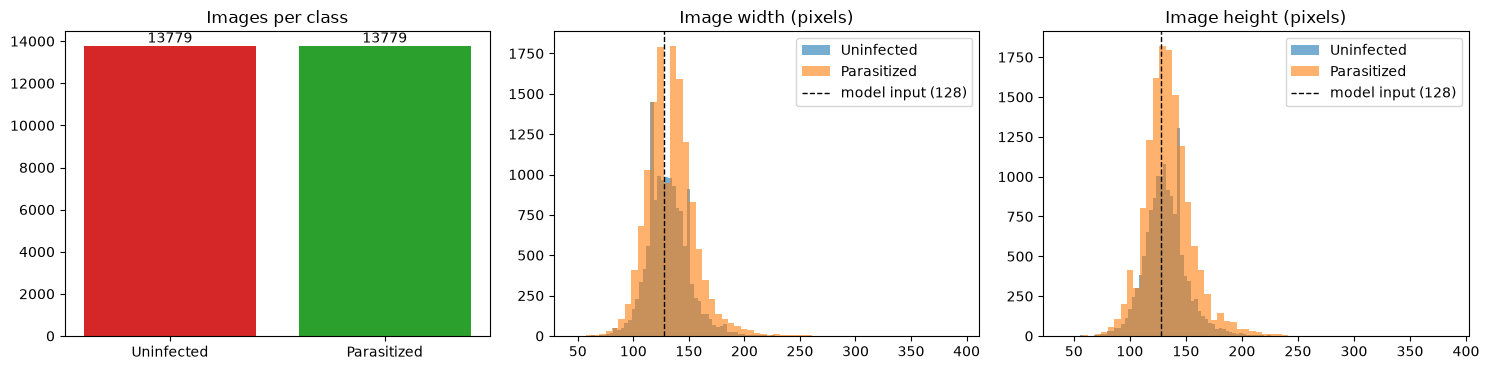

          count   mean   std   min    25%    50%    75%    max
width   27558.0  132.5  20.0  46.0  121.0  130.0  142.0  394.0
height  27558.0  133.0  20.6  40.0  121.0  130.0  145.0  385.0

58.8% of images are smaller than 128 px on at least one side (they are enlarged).
20 images are below 64 px; the smallest side is 40 px, so the strongest upscaling factor is 3.2x.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(counts.index, counts.values, color=["tab:red", "tab:green"])
axes[0].set_title("Images per class")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v}", ha="center", va="bottom")
for ax, col in zip(axes[1:], ["width", "height"]):
    for label, name in enumerate(mu.CLASS_NAMES):
        ax.hist(df.loc[df.label == label, col], bins=60, alpha=0.6, label=name)
    ax.axvline(128, color="k", ls="--", lw=1, label="model input (128)")
    ax.set_title(f"Image {col} (pixels)")
    ax.legend()
plt.tight_layout()
plt.show()

print(df[["width", "height"]].describe().round(1).T)
small = ((df.width < 128) | (df.height < 128)).mean()
tiny = ((df.width < 64) | (df.height < 64)).sum()
smallest = min(df.width.min(), df.height.min())
print(f"\n{small:.1%} of images are smaller than 128 px on at least one side (they are enlarged).")
print(f"{tiny} images are below 64 px; the smallest side is {smallest} px, "
      f"so the strongest upscaling factor is {128 / smallest:.1f}x.")

**Observations** (the exact numbers are printed above)

* The two classes have **exactly the same number of images**, so accuracy is a meaningful metric and no
  class weighting or resampling is needed.
* No file is corrupt. Exact duplicates are checked after the split (section 2).
* Image sizes vary a lot, because each image is a crop around one cell. All images are resized to
  **128 × 128**, close to the median size.
* **Upscaling is unavoidable for some images.** More than half of the images are slightly smaller than 128 px
  on at least one side and are enlarged a little. A small group of very small cells is enlarged by the factor
  printed above, about 3×, and looks blurry to the network. The largest images are shrunk. Resizing to a
  square also slightly squashes cells that are not round. A fixed size is required for batching, and
  128 px keeps most images close to their original resolution.

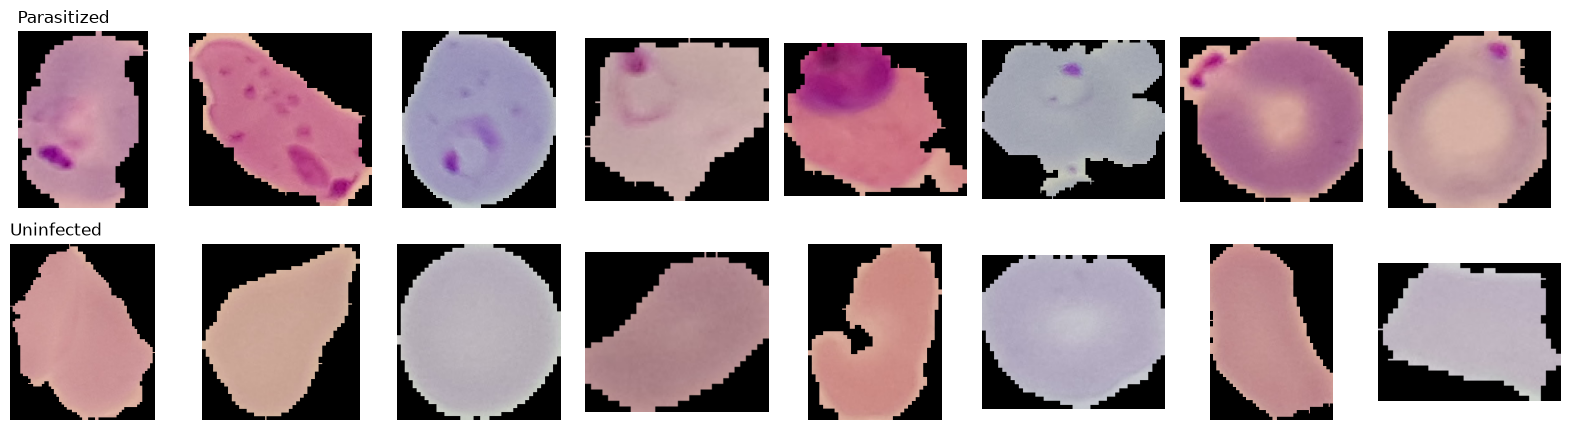

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, label in enumerate([1, 0]):
    sample = df[df.label == label].sample(8, random_state=mu.SEED)
    for ax, p in zip(axes[row], sample["path"]):
        ax.imshow(Image.open(mu.PROJECT_DIR / p))
        ax.axis("off")
    axes[row, 0].set_title(mu.CLASS_NAMES[label], loc="left", fontsize=12)
plt.tight_layout()
plt.show()

**What the classes look like.** The Giemsa stain colours the parasite's DNA dark **purple**. Parasitized
cells show one or more purple **dots, rings or irregular blobs** inside the pink cell (ring-stage
trophozoites, sometimes larger schizonts or gametocytes). Uninfected cells are a smooth, uniform pink or
pale violet disc, sometimes with faint, diffuse staining variations but no compact dark spot. The
background outside the cell is black (the cells were segmented from the slide). The colour and texture
of a small region inside the cell decide the class, which is the kind of local pattern convolutions are good at.

## 2. Preprocessing and data pipeline

### 2.1 Train / validation / test split

The split is made on **file paths, before any training**: 70 % train, 15 % validation, 15 % test,
**stratified** so each part keeps the 50/50 class balance. It is saved to `outputs/splits/*.csv`, and
`train.py` and this notebook both reload the same files, so the split is reproducible.

* **train**: used to learn the weights
* **validation**: used for early stopping, learning-rate reduction and choosing the decision threshold
* **test**: used **once**, at the very end, for the reported results

In [6]:
splits = mu.load_or_create_splits()
summary = pd.DataFrame({name: part["label"].map(dict(enumerate(mu.CLASS_NAMES))).value_counts()
                        for name, part in splits.items()}).T
summary["total"] = summary.sum(axis=1)
summary["share"] = (summary["total"] / summary["total"].sum()).map("{:.0%}".format)
summary

label,Parasitized,Uninfected,total,share
train,9645,9645,19290,70%
val,2067,2067,4134,15%
test,2067,2067,4134,15%


In [7]:
# Leakage check: hash every file and look for identical images shared between splits
overlap = mu.check_split_overlap(splits)
print("identical files shared between splits:", overlap)
print("OK: no identical image in two splits" if not any(overlap.values())
      else "WARNING: duplicates across splits - test scores would be optimistic")

identical files shared between splits: {'train-val': 0, 'train-test': 0, 'val-test': 0}
OK: no identical image in two splits


MD5 hashing only catches exact copies. Two different photos of the same cell, or crops that differ
slightly, would not be detected.

**Limitation: no patient-level split.** The Kaggle version of the dataset has no patient IDs, so cells
from the same patient (and the same slide, with the same staining and lighting) can end up in both
train and test. The model may partly learn slide-specific appearance, so the test scores are probably
**slightly optimistic** compared with completely new patients.

### 2.2 Resizing, scaling and augmentation

* Every image is resized to 128 × 128 and converted to a tensor with pixel values in **[0, 1]**.
* For MobileNetV2 the ImageNet normalisation (subtract the mean, divide by the standard deviation per
  channel) is done **inside the model**, so both models take the same input.
* **Augmentation on the training set only**: random horizontal/vertical flips, rotation by any angle,
  zoom of ±10 % and a ±10 % brightness change. A cell under the microscope has no "up" direction, so
  flips and rotations create realistic new examples, and the black background matches the corners
  filled in by the rotation. Validation and test images are only resized, never augmented.

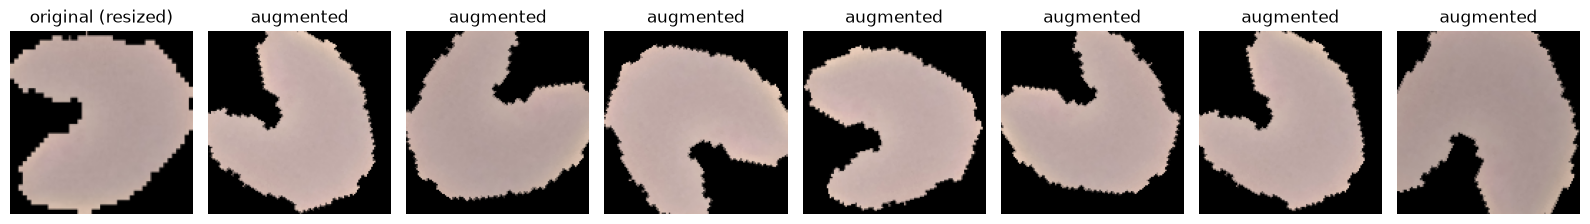

In [8]:
example = Image.open(mu.PROJECT_DIR / df[df.label == 1].sample(1, random_state=3)["path"].iloc[0]).convert("RGB")
aug = mu.get_transform(128, train=True)
plain = mu.get_transform(128, train=False)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(plain(example).permute(1, 2, 0))
axes[0].set_title("original (resized)")
torch.manual_seed(0)
for ax in axes[1:]:
    ax.imshow(aug(example).permute(1, 2, 0))
    ax.set_title("augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2.3 Efficient loading

`CellDataset` reads one image from disk only when it is needed, and a PyTorch `DataLoader` groups
images into **batches of 64**. The whole dataset is never loaded into RAM.

* `num_workers=4`: four background processes decode and augment images while the GPU trains on the
  previous batch. `persistent_workers=True` keeps them alive between epochs. On Windows, starting the
  workers takes tens of seconds, because each one imports PyTorch.
* `pin_memory=True` makes copying the batch to the GPU faster.
* All training code in `train.py` is under `if __name__ == "__main__":`. Windows starts workers by
  re-importing the script, and without the guard each worker would start training again.

**A Windows-specific problem found during development.** Every worker process loads PyTorch's CUDA
libraries and reserves a lot of virtual memory (about 2.5 GB each on this machine). The first version
used 4 workers each for the train, validation and test loaders (12 processes). It crashed with
`WinError 1455: The paging file is too small`. Now only the training loader uses workers, and validation
and test images (no augmentation, read once per epoch) are loaded in the main process.

In [9]:
x, y = next(iter(mu.make_loader(splits["train"], 128, 64, train=True, num_workers=0)))
print("batch of images:", tuple(x.shape), x.dtype, f"values in [{x.min():.2f}, {x.max():.2f}]")
print("batch of labels:", tuple(y.shape), "->", y[:10].tolist())

batch of images: (64, 3, 128, 128) torch.float32 values in [0.00, 0.99]
batch of labels: (64,) -> [0.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0]


## 3. Models

### 3.1 Custom CNN from scratch (main model)

Four convolutional blocks, each **Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2** with 32, 64, 128 and 128
filters, then **global average pooling → Dropout(0.5) → Dense(64) → Dense(1)**.

| Layer | What it does |
|---|---|
| **Conv2d (3×3)** | Slides small learnable filters over the image. Early layers detect edges and colour blobs, deeper layers combine them into shapes such as a purple ring. |
| **BatchNorm** | Normalises each channel over the batch, which makes training faster and more stable. |
| **ReLU** | Non-linearity `max(0, x)`. Without it, the stacked layers would collapse into one linear function. |
| **MaxPool 2×2** | Keeps the strongest response in each 2×2 area, halving the size (128 → 64 → 32 → 16 → 8). It gives some tolerance to small shifts and lets later filters see a larger part of the cell. |
| **Global average pooling** | Averages each of the 128 feature maps to one number. It has far fewer parameters than flattening, so it overfits less, and it does not care *where* in the cell the parasite is. |
| **Dropout(0.5)** | During training, randomly switches off half of the features, so the network cannot rely on a few of them (regularisation). |
| **Dense / Linear** | A fully connected layer that combines the features into the decision. |
| **Output + sigmoid** | One number (logit). `sigmoid(logit)` is the probability of *Parasitized*. Training uses `BCEWithLogitsLoss`, which applies the sigmoid inside the loss. That is numerically stable and safe with mixed precision. |

**Why this model:** the task asks for a CNN, and the visual signal (a dark stained spot inside a cell) is
simple and local, so a small network should be enough. It is tiny (parameter count printed below), which
means short training and fast inference.

In [10]:
cnn = mu.MalariaCNN()
print(cnn)
print(f"\nparameters: {mu.count_params(cnn):,}")

MalariaCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13): BatchNorm2d(128, eps=1e-05, mom

### 3.2 Transfer-learning comparison: MobileNetV2

MobileNetV2 pretrained on ImageNet (1.2 M everyday photos) from `torchvision`. Its 1000-class classifier is
replaced by **Dropout(0.3) → Linear(1280 → 1)**. It is trained in two stages:

1. **Frozen base**: only the new head learns. The pretrained features are kept as they are.
2. **Fine-tuning**: the top 5 blocks of the base are unfrozen and adapted to cell images with a
   **10× lower learning rate**, so the pretrained weights are adjusted gently instead of being destroyed
   by large updates. BatchNorm layers in still-frozen blocks keep their ImageNet statistics.

**Why this model:** it answers the question *"does a network pretrained on millions of images beat a small CNN
trained from scratch?"*. MobileNetV2 was designed for phones (depthwise-separable convolutions), so it runs
comfortably on a laptop.

In [11]:
mobilenet = mu.MobileNetClassifier(pretrained=False)
print(mobilenet.classifier)
print(f"parameters: {mu.count_params(mobilenet):,}  (about {mu.count_params(mobilenet) / mu.count_params(cnn):.0f}x the custom CNN)")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Dropout(p=0.3, inplace=False)
  (2): Linear(in_features=1280, out_features=1, bias=True)
)
parameters: 2,225,153  (about 9x the custom CNN)


### 3.3 Training settings

* Loss: binary cross-entropy (`BCEWithLogitsLoss`); optimiser: **Adam**.
* **Mixed precision** (`torch.autocast` with float16 and a gradient scaler): faster on the RTX GPU and uses less memory.
* **Early stopping**: stop when the validation loss has not improved for `patience` epochs, and restore the best weights.
* **ReduceLROnPlateau**: halve the learning rate when the validation loss stalls for 2 epochs.
* **Checkpoint**: the best model (lowest validation loss) is saved to `outputs/<model>_best.pt`.
* Tracked every epoch: loss, accuracy, precision, recall and AUC on validation, plus epoch time and GPU utilisation.
* Seeds are set to 42. `cudnn.benchmark` is on for speed, so GPU results can differ very slightly between runs.

The settings of the last run (read from `outputs/run_info.json`) and its full log:

In [12]:
if RETRAIN:
    subprocess.run([sys.executable, "train.py"], check=True, cwd=mu.PROJECT_DIR)

results, run_info = mu.load_results()
s = run_info["settings"]
print(f"Run finished {run_info['finished']} on {run_info['gpu']}, total time {run_info['total_minutes']:.1f} min")
print(f"Custom CNN : max {s['epochs']} epochs, lr {s['lr']:g}")
print(f"MobileNetV2: frozen stage {s['frozen_epochs']} epochs (lr {s['lr']:g}), "
      f"fine-tuning max {s['ft_epochs']} epochs (lr {s['ft_lr']:g}), top {s['unfreeze_blocks']} blocks")
print(f"Early-stopping patience {s['patience']}, image size {s['img_size']}, batch size {s['batch_size']}, "
      f"{s['num_workers']} workers, target recall {s['target_recall']}")
print()
print((OUT / "training_log.txt").read_text(encoding="utf-8"))

Run finished 2026-10-18 16:25 on NVIDIA GeForce RTX 5050 Laptop GPU, total time 12.0 min
Custom CNN : max 50 epochs, lr 0.001
MobileNetV2: frozen stage 5 epochs (lr 0.001), fine-tuning max 20 epochs (lr 0.0001), top 5 blocks
Early-stopping patience 5, image size 128, batch size 64, 4 workers, target recall 0.98

Malaria cell classification - training run 2026-10-18 16:13
Mode       : full training
GPU        : NVIDIA GeForce RTX 5050 Laptop GPU
Software   : Python 3.11.3, PyTorch 2.11.0+cu128
Settings   : {'model': 'both', 'epochs': 50, 'frozen_epochs': 5, 'ft_epochs': 20, 'img_size': 128, 'batch_size': 64, 'lr': 0.001, 'ft_lr': 0.0001, 'unfreeze_blocks': 5, 'patience': 5, 'num_workers': 4, 'target_recall': 0.98, 'quick': False}
Split sizes: train=19290, val=4134, test=4134
Identical files shared between splits (MD5): {'train-val': 0, 'train-test': 0, 'val-test': 0}
Started 4 DataLoader workers in 17.7s

===== Custom CNN =====
Parameters: 249,505
[cnn] epoch  1/50 |  19.7s | GPU  27% |

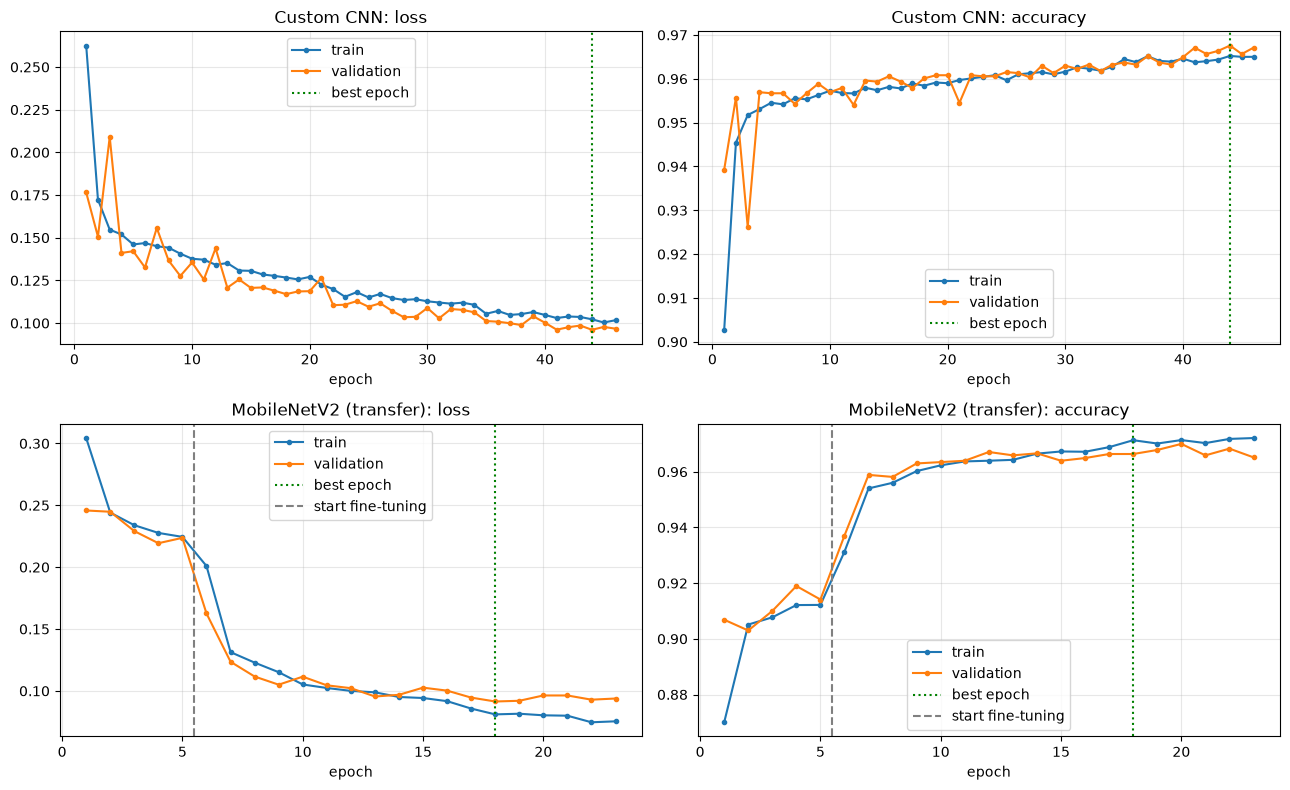

In [13]:
hist = {name: pd.read_csv(OUT / f"history_{name}.csv") for name in ["cnn", "mobilenet"]}
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, name in enumerate(["cnn", "mobilenet"]):
    h = hist[name]
    x = np.arange(1, len(h) + 1)
    for ax, key in zip(axes[row], ["loss", "acc"]):
        ax.plot(x, h[f"train_{key}"], "o-", ms=3, label="train")
        ax.plot(x, h[f"val_{key}"], "o-", ms=3, label="validation")
        ax.axvline(h["val_loss"].idxmin() + 1, color="green", ls=":", label="best epoch")
        if h["stage"].nunique() > 1:
            ax.axvline((h["stage"] == "finetune").idxmax() + 0.5, color="gray", ls="--", label="start fine-tuning")
        ax.set_title(f"{mu.MODEL_LABELS[name]}: {'loss' if key == 'loss' else 'accuracy'}")
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.show()

**Reading the curves.** The comments below are generated from the training histories. A gap between
training and validation accuracy that keeps growing would mean **overfitting** (the model memorises the
training images). A validation loss *below* the training loss is normal here: dropout and augmentation
are only active during training, so the training batches are harder than the validation images.

In [14]:
def describe_curves(name):
    h = hist[name]
    row = results[results.model == mu.MODEL_LABELS[name]].iloc[0]
    best = h["val_loss"].idxmin()
    gap = h.train_acc[best] - h.val_acc[best]
    verdict = ("no sign of overfitting" if gap < 0.01 else
               "mild overfitting" if gap < 0.03 else "clear overfitting")
    out = [f"**{mu.MODEL_LABELS[name]}**: {row.epoch_summary}. Training took {row.train_minutes:.1f} min "
           f"({h.seconds.median():.1f} s per epoch, median).",
           f"* At the best epoch, train accuracy is {h.train_acc[best]:.2%} and validation accuracy "
           f"{h.val_acc[best]:.2%} (gap {100 * gap:+.1f} points): **{verdict}**."]
    if (h.val_loss < h.train_loss).mean() > 0.5:
        out.append("* The validation loss is below the training loss for most epochs (dropout and augmentation effect).")
    # a spike = validation loss more than twice the best value seen so far in the same stage
    running_best = h.groupby("stage").val_loss.cummin().groupby(h.stage).shift()
    spikes = h.index[h.val_loss > 2 * running_best] + 1
    if len(spikes):
        out.append(f"* Validation-loss spike(s) at epoch(s) {', '.join(map(str, spikes))}: a short training "
                   "instability. The model recovered, and checkpointing keeps the best weights anyway.")
    out.append("* Early stopping ended training." if row.stopped_early else
               "* The epoch limit ended training, not early stopping, so the model might still improve slightly.")
    if name == "mobilenet":
        frozen, ft = h[h.stage == "frozen"], h[h.stage == "finetune"]
        out.append(f"* With the base frozen, validation accuracy reaches at most {frozen.val_acc.max():.2%}. "
                   f"Fine-tuning raises it to {ft.val_acc.max():.2%}"
                   + (": ImageNet features alone do not fit stained blood cells well, and adapting the top blocks matters."
                      if ft.val_acc.max() > frozen.val_acc.max() + 0.01 else "."))
    return "\n".join(out)

display(Markdown("\n\n".join(describe_curves(n) for n in ["cnn", "mobilenet"])))

**Custom CNN**: stopped early at epoch 46 of 50 (best epoch 44). Training took 7.1 min (9.0 s per epoch, median).
* At the best epoch, train accuracy is 96.52% and validation accuracy 96.76% (gap -0.2 points): **no sign of overfitting**.
* The validation loss is below the training loss for most epochs (dropout and augmentation effect).
* Early stopping ended training.

**MobileNetV2 (transfer)**: frozen: ran all 5 epochs (best epoch 4); fine-tune: stopped early at epoch 18 of 20 (best epoch 13). Training took 3.8 min (8.8 s per epoch, median).
* At the best epoch, train accuracy is 97.13% and validation accuracy 96.64% (gap +0.5 points): **no sign of overfitting**.
* Early stopping ended training.
* With the base frozen, validation accuracy reaches at most 91.90%. Fine-tuning raises it to 97.00%: ImageNet features alone do not fit stained blood cells well, and adapting the top blocks matters.

## 4. Evaluation on the held-out test set

The best checkpoints are loaded and evaluated on the test images. Neither model has ever seen
them, and the test set was not used for any decision during training.

**Parasitized is the positive class.** Recall (sensitivity) = the share of infected cells that are
detected. Specificity = the share of healthy cells correctly called healthy.

In [15]:
test_loader = mu.make_loader(splits["test"], 128, 64, train=False, num_workers=0)
val_loader = mu.make_loader(splits["val"], 128, 64, train=False, num_workers=0)
models_, ckpts, probs, val_probs = {}, {}, {}, {}
for name in ["cnn", "mobilenet"]:
    models_[name], ckpts[name] = mu.load_checkpoint(OUT / f"{name}_best.pt", device)
    logits, y_test = mu.predict_logits(models_[name], test_loader, device)
    probs[name] = mu.sigmoid(logits)
    vlogits, y_val = mu.predict_logits(models_[name], val_loader, device)
    val_probs[name] = mu.sigmoid(vlogits)
print(f"test set: {len(y_test)} images ({y_test.sum()} Parasitized, {(y_test == 0).sum()} Uninfected)")

rows = []
for name in ["cnn", "mobilenet"]:
    thr_tuned = ckpts[name]["threshold"]
    for thr_name, thr in [("0.50 (default)", 0.5), (f"{thr_tuned:.3f} (tuned on val)", thr_tuned)]:
        m = mu.compute_metrics(y_test, probs[name], thr)
        rows.append({"model": mu.MODEL_LABELS[name], "threshold": thr_name, **m})
table = pd.DataFrame(rows)
table[["model", "threshold", "accuracy", "precision", "recall", "specificity", "f1", "auc", "fn", "fp"]]

test set: 4134 images (2067 Parasitized, 2067 Uninfected)


,model,threshold,accuracy,precision,recall,specificity,f1,auc,fn,fp
0,Custom CNN,0.50 (default),0.9657,0.9734,0.9574,0.9739,0.9654,0.9927,88,54
1,Custom CNN,0.176 (tuned on val),0.9555,0.9389,0.9744,0.9366,0.9563,0.9927,53,131
2,MobileNetV2 (transfer),0.50 (default),0.9615,0.9775,0.9448,0.9782,0.9609,0.9937,114,45
3,MobileNetV2 (transfer),0.281 (tuned on val),0.9649,0.9589,0.9715,0.9584,0.9652,0.9937,59,86


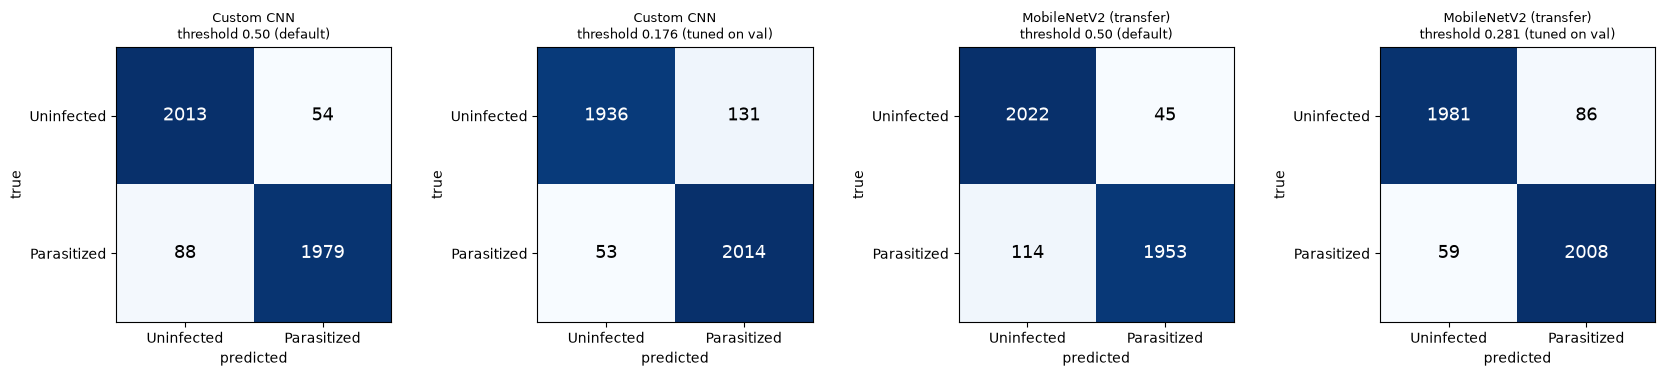

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (_, r) in zip(axes, table.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], mu.CLASS_NAMES)
    ax.set_yticks([0, 1], mu.CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{r.model}\nthreshold {r.threshold}", fontsize=9)
plt.tight_layout()
plt.show()

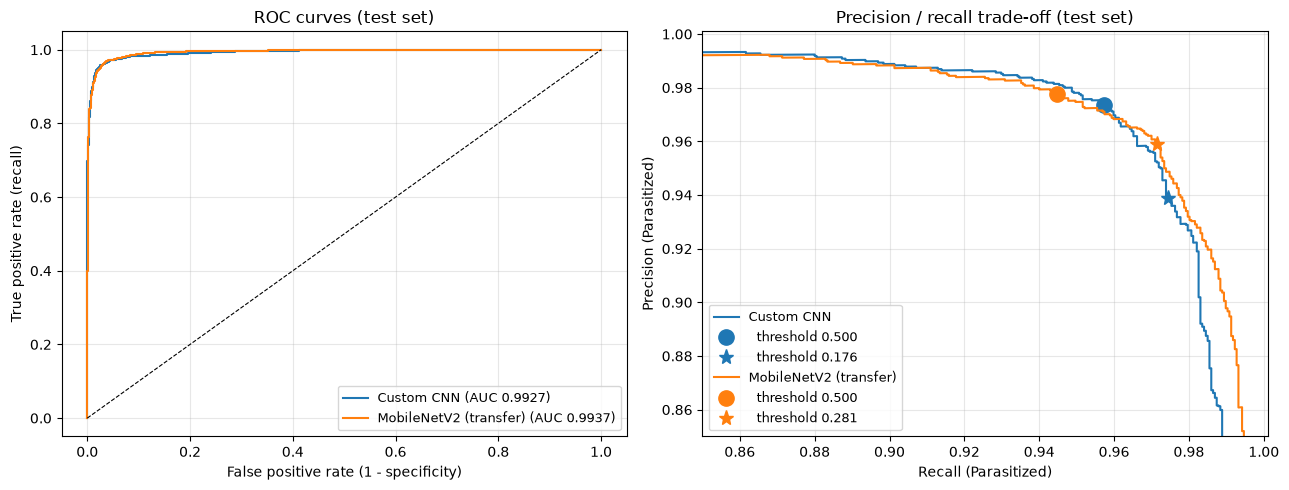

In [17]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["cnn", "mobilenet"]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    auc = mu.compute_metrics(y_test, probs[name])["auc"]
    axes[0].plot(fpr, tpr, label=f"{mu.MODEL_LABELS[name]} (AUC {auc:.4f})")
    prec, rec, thr = precision_recall_curve(y_test, probs[name])
    line, = axes[1].plot(rec, prec, label=mu.MODEL_LABELS[name])
    for t, marker in [(0.5, "o"), (ckpts[name]["threshold"], "*")]:
        m = mu.compute_metrics(y_test, probs[name], t)
        axes[1].plot(m["recall"], m["precision"], marker, ms=11, color=line.get_color(),
                     label=f"  threshold {t:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)",
            title="ROC curves (test set)")
axes[1].set(xlabel="Recall (Parasitized)", ylabel="Precision (Parasitized)",
            title="Precision / recall trade-off (test set)", xlim=(0.85, 1.001), ylim=(0.85, 1.001))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left" if ax is axes[1] else "lower right", fontsize=9)
plt.tight_layout()
plt.show()

### 4.1 Why recall on the Parasitized class matters most

The two kinds of error have very different costs:

* **False negative** (an infected cell called healthy): the patient may go untreated. Malaria,
  especially *P. falciparum*, can become severe or fatal within days.
* **False positive** (a healthy cell flagged as infected): the sample is re-checked by a technician or
  the test is repeated. That is inconvenient but harmless.

So the model should be tuned for **high recall**, accepting some extra false alarms. The default threshold
of 0.5 treats both errors as equally bad. The threshold is therefore lowered: it is chosen on the
**validation set** as the highest threshold (at most 0.5) that reaches the target recall
(`--target-recall`), then applied unchanged to the test set. The table shows the trade-off on the
validation set.

In [18]:
rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    row = {"threshold": t}
    for name, short in [("cnn", "CNN"), ("mobilenet", "MobileNet")]:
        m = mu.compute_metrics(y_val, val_probs[name], t)
        row[f"{short} recall"] = m["recall"]
        row[f"{short} precision"] = m["precision"]
        row[f"{short} missed (FN)"] = m["fn"]
        row[f"{short} false alarms (FP)"] = m["fp"]
    rows.append(row)
print(f"Validation set ({(y_val == 1).sum()} infected and {(y_val == 0).sum()} healthy cells), "
      f"target recall {run_info['settings']['target_recall']}")
pd.DataFrame(rows).set_index("threshold").round(4)

Validation set (2067 infected and 2067 healthy cells), target recall 0.98


,CNN recall,CNN precision,CNN missed (FN),CNN false alarms (FP),MobileNet recall,MobileNet precision,MobileNet missed (FN),MobileNet false alarms (FP)
threshold,,,,,,,,
0.05,0.9908,0.8623,19,327,0.9961,0.8353,8,406
0.10,0.9850,0.9142,31,191,0.9927,0.8906,15,252
0.20,0.9782,0.9413,45,126,0.9855,0.9431,30,123
0.30,0.9739,0.9549,54,95,0.9768,0.9601,48,84
0.40,0.9700,0.9616,62,80,0.9695,0.9681,63,66
0.50,0.9637,0.9703,75,61,0.9560,0.9744,91,52
0.60,0.9579,0.9749,87,51,0.9492,0.9805,105,39
0.70,0.9511,0.9801,101,40,0.9419,0.9838,120,32


In [22]:
for name in ["cnn", "mobilenet"]:
    stored = ckpts[name]["threshold"]
    on_val = mu.threshold_for_recall(y_val, val_probs[name], target)
    on_test = mu.threshold_for_recall(y_test, probs[name], target)
    print(f"{name}: stored={stored:.6f}  val={on_val:.6f}  test={on_test:.6f}  target_recall={target}")

cnn: stored=0.176246  val=0.175908  test=0.133226  target_recall=0.98
mobilenet: stored=0.280814  val=0.281976  test=0.182618  target_recall=0.98


In [23]:
target = run_info["settings"]["target_recall"]
lines = []
for name in ["cnn", "mobilenet"]:
    stored = ckpts[name]["threshold"]
    on_val = mu.threshold_for_recall(y_val, val_probs[name], target)
    on_test = mu.threshold_for_recall(y_test, probs[name], target)
    close_to_val = abs(stored - on_val) <= 0.005          # same search, numerical noise only
    nearer_val = abs(stored - on_val) < abs(stored - on_test)  # clearly not test-tuned
    lines.append(f"* **{mu.MODEL_LABELS[name]}**: stored {stored:.4f}, re-tuned on validation {on_val:.4f} "
                 f"(difference {abs(stored-on_val):.4f}); the same search on test would give {on_test:.4f}.")
    assert close_to_val and nearer_val, f"{name}: stored threshold does not look validation-tuned"
display(Markdown("**Thresholds were tuned on validation only** (tiny differences are numerical noise).\n\n" + "\n".join(lines)))

**Thresholds were tuned on validation only** (tiny differences are numerical noise).

* **Custom CNN**: stored 0.1762, re-tuned on validation 0.1759 (difference 0.0003); the same search on test would give 0.1332.
* **MobileNetV2 (transfer)**: stored 0.2808, re-tuned on validation 0.2820 (difference 0.0012); the same search on test would give 0.1826.

In [24]:
# Effect of the tuned threshold on the TEST set, computed from outputs/results.csv
target = run_info["settings"]["target_recall"]
lines = []
tuned = {}
for model, g in results.groupby("model", sort=False):
    d = g[g.threshold.str.contains("default")].iloc[0]
    t = g[g.threshold.str.contains("tuned")].iloc[0]
    tuned[model] = t
    lines.append(f"* **{model}**, threshold {t.threshold.split()[0]}: missed infections {d.fn} → **{t.fn}** "
                 f"({(d.fn - t.fn) / max(d.fn, 1):.0%} fewer), false alarms {d.fp} → {t.fp}. "
                 f"Recall {d.recall:.2%} → **{t.recall:.2%}**, specificity {d.specificity:.2%} → {t.specificity:.2%}.")
(m1, r1), (m2, r2) = tuned.items()
fewer = m1 if r1.fp < r2.fp else m2
lines.append(f"\nTest recall at the tuned thresholds is {r1.recall:.2%} and {r2.recall:.2%}, against a target of "
             f"{target:.0%} set on validation. Moving a threshold to new data usually loses a little. "
             f"At similar recall, **{fewer}** raises fewer false alarms ({min(r1.fp, r2.fp)} vs {max(r1.fp, r2.fp)}).")
display(Markdown("\n".join(lines)))

* **Custom CNN**, threshold 0.176: missed infections 88 → **53** (40% fewer), false alarms 54 → 131. Recall 95.74% → **97.44%**, specificity 97.39% → 93.66%.
* **MobileNetV2 (transfer)**, threshold 0.281: missed infections 113 → **58** (49% fewer), false alarms 46 → 86. Recall 94.53% → **97.19%**, specificity 97.77% → 95.84%.

Test recall at the tuned thresholds is 97.44% and 97.19%, against a target of 98% set on validation. Moving a threshold to new data usually loses a little. At similar recall, **MobileNetV2 (transfer)** raises fewer false alarms (86 vs 131).

### 4.2 Misclassified test images

For each model, the test images it is **most confident about while being wrong** (at its tuned threshold).

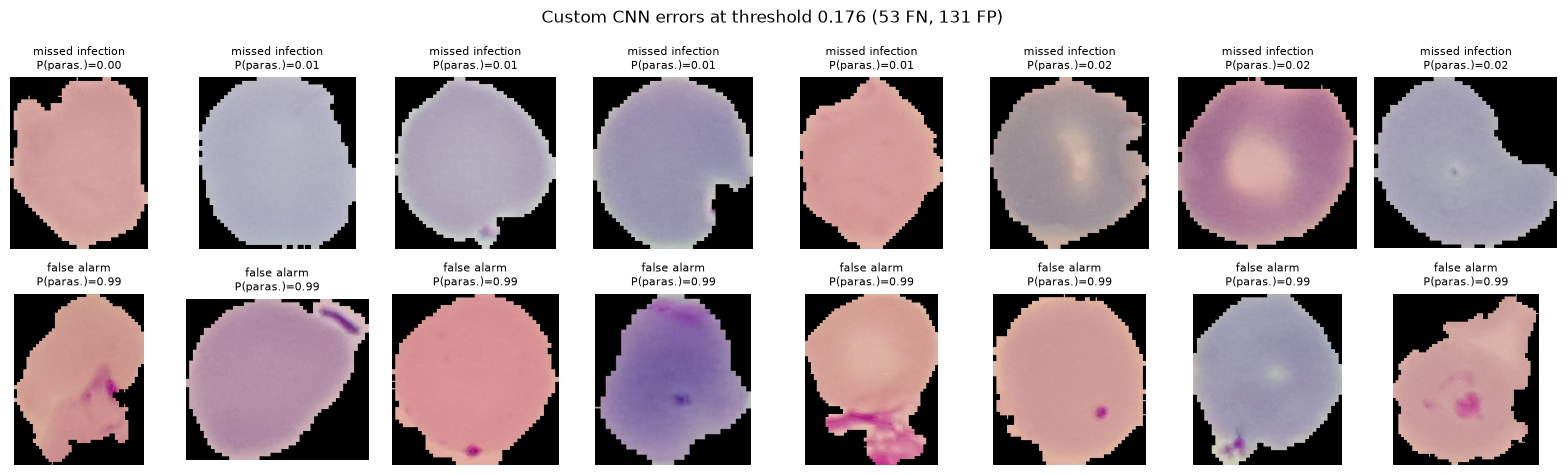

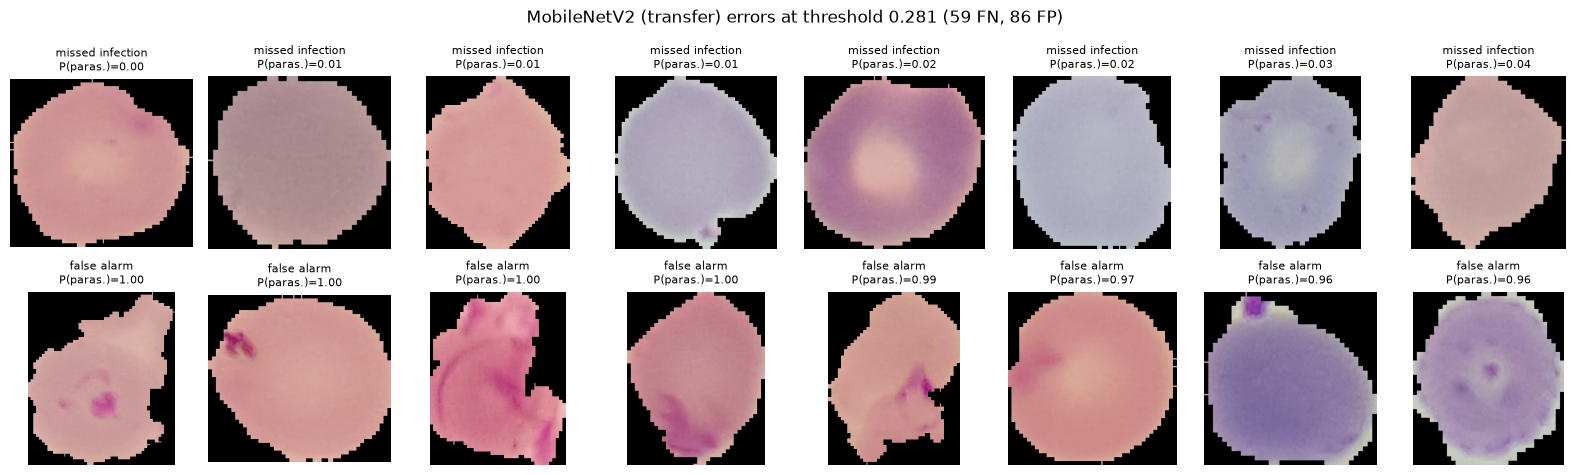

In [25]:
paths = splits["test"]["path"].to_numpy()

def show_errors(name, n=8):
    p, thr = probs[name], ckpts[name]["threshold"]
    pred = (p >= thr).astype(int)
    fn_all = np.where((y_test == 1) & (pred == 0))[0]
    fp_all = np.where((y_test == 0) & (pred == 1))[0]
    fn = fn_all[np.argsort(p[fn_all])][:n]       # most confident misses first
    fp = fp_all[np.argsort(-p[fp_all])][:n]      # most confident false alarms first
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.8))
    for row, (idx, title) in enumerate([(fn, "missed infection"), (fp, "false alarm")]):
        for ax in axes[row]:
            ax.axis("off")
        for ax, i in zip(axes[row], idx):
            ax.imshow(Image.open(mu.PROJECT_DIR / paths[i]))
            ax.set_title(f"{title}\nP(paras.)={p[i]:.2f}", fontsize=8)
    fig.suptitle(f"{mu.MODEL_LABELS[name]} errors at threshold {thr:.3f} ({len(fn_all)} FN, {len(fp_all)} FP)")
    plt.tight_layout()
    plt.show()

for name in ["cnn", "mobilenet"]:
    show_errors(name)

**Why are these images hard?** Looking at the most confident errors:

* **Possible label errors.** Some "false alarms" (labelled Uninfected) clearly contain a compact dark
  purple dot or ring inside the cell, which is exactly what a parasite looks like, and the models are very
  sure about them. Some "missed infections" (labelled Parasitized) show a uniform cell with no visible
  stained structure. These look more like **labelling mistakes in the dataset** than model mistakes. Label
  noise in this dataset has been reported before, and it limits the accuracy any model can reach (and that
  we can measure).
* **Stain debris and overlapping objects.** Some false alarms have purple material only at the **edge** of the
  cell or outside it (a platelet, stain precipitate, or a piece of a neighbouring cell left by the
  segmentation). The model notices "purple blob" but cannot tell whether it is inside the cell.
* **Faint or small parasites.** Some infected cells have only a tiny, pale spot near the border. After
  resizing (especially for small images that were upscaled) this signal is weak and blurry.
* **Staining and colour variation.** Cells range from pink to grey to lilac between slides. A purple-tinted
  healthy cell, or a pale infected one, is harder to judge.

### 4.3 Grad-CAM: where does the model look?

**Grad-CAM** takes the gradient of the output with respect to the last convolutional feature maps,
which shows which regions of the image pushed the prediction towards its class. Red means important.
For a medical model this is an important sanity check: a trustworthy model should focus on the
**purple parasite inside the cell**, not on the black background, the cell border or staining artefacts.

Columns: two correct Parasitized (TP), two correct Uninfected (TN), two missed infections (FN) and two
false alarms (FP), picked at random with a fixed seed.

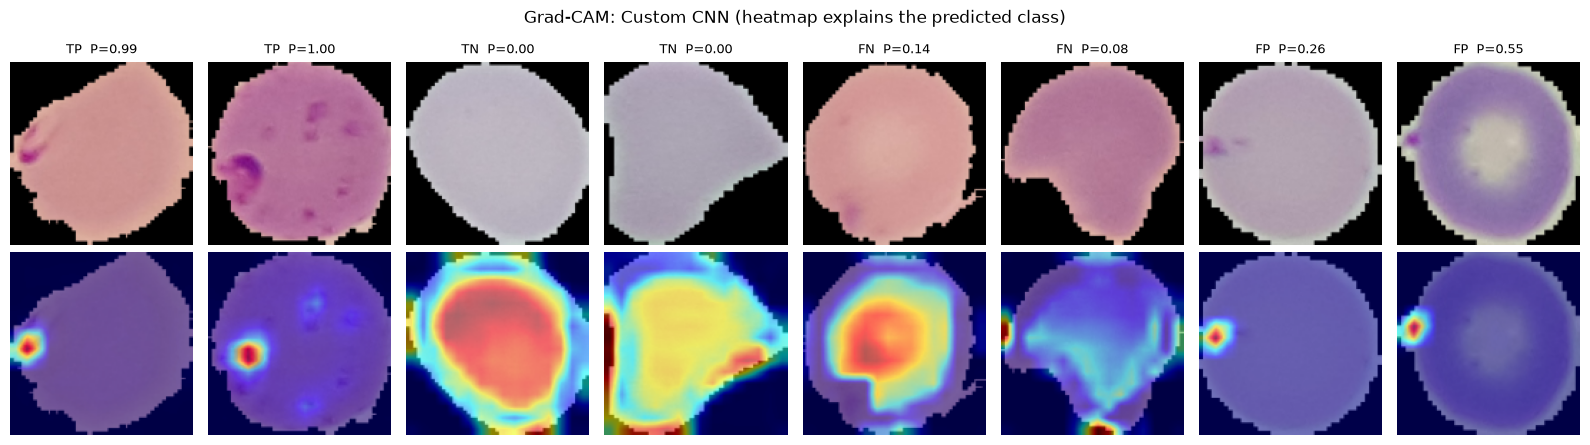

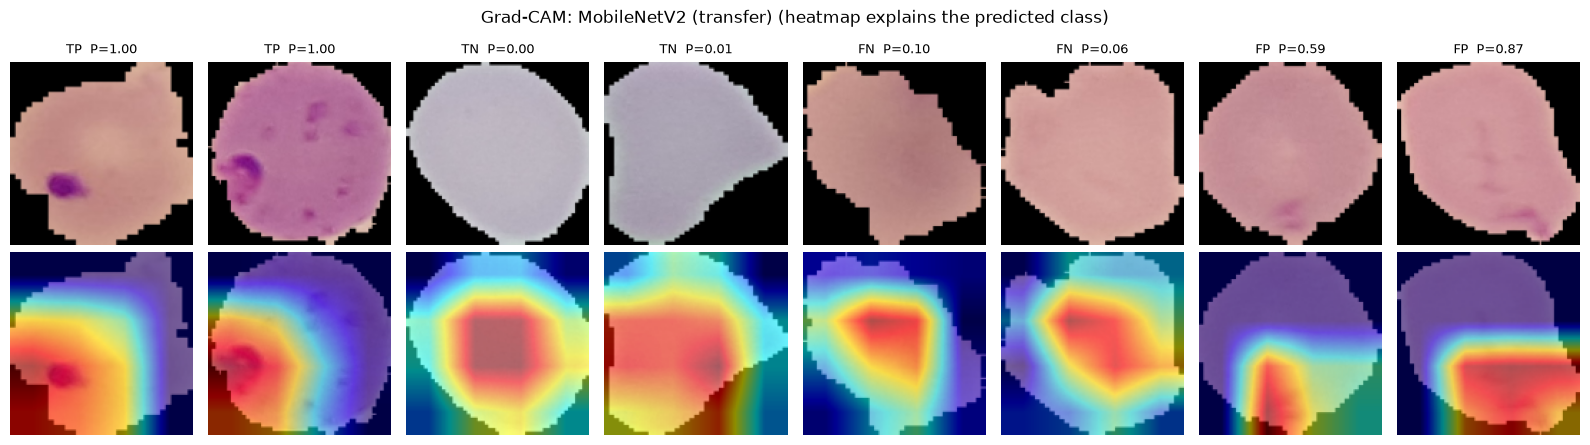

In [26]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import BinaryClassifierOutputTarget

def pick_examples(name, k=2):
    p, thr = probs[name], ckpts[name]["threshold"]
    pred = (p >= thr).astype(int)
    rng = np.random.default_rng(mu.SEED)
    groups = [("TP", (y_test == 1) & (pred == 1)), ("TN", (y_test == 0) & (pred == 0)),
              ("FN", (y_test == 1) & (pred == 0)), ("FP", (y_test == 0) & (pred == 1))]
    picked = []
    for tag, mask in groups:
        idx = np.where(mask)[0]
        for i in rng.choice(idx, size=min(k, len(idx)), replace=False):
            picked.append((tag, i, int(pred[i])))
    return picked

def show_gradcam(name):
    model = models_[name].float().eval()
    transform = mu.get_transform(128, train=False)
    examples = pick_examples(name)
    fig, axes = plt.subplots(2, len(examples), figsize=(2 * len(examples), 4.6))
    with GradCAM(model=model, target_layers=[model.gradcam_layer()]) as cam:
        for col, (tag, i, pred) in enumerate(examples):
            x = transform(Image.open(mu.PROJECT_DIR / paths[i]).convert("RGB"))
            heat = cam(input_tensor=x.unsqueeze(0).to(device),
                       targets=[BinaryClassifierOutputTarget(pred)])[0]   # explain the predicted class
            rgb = x.permute(1, 2, 0).numpy()
            axes[0, col].imshow(rgb)
            axes[0, col].set_title(f"{tag}  P={probs[name][i]:.2f}", fontsize=9)
            axes[1, col].imshow(show_cam_on_image(rgb, heat, use_rgb=True))
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(f"Grad-CAM: {mu.MODEL_LABELS[name]} (heatmap explains the predicted class)")
    plt.tight_layout()
    plt.show()

for name in ["cnn", "mobilenet"]:
    show_gradcam(name)

**What Grad-CAM shows**

* **Custom CNN.** For correctly detected infections the heatmap is a **sharp hot spot on the purple
  parasite**, and it ignores the rest of the cell and the background. That is the behaviour we want from a
  medical model. For healthy cells there is no single spot to point at, so the evidence for "Uninfected" is
  spread over the cell body and its border. Where false alarms occur, the hot spots tend to sit on the
  **cell edge** (purple material just outside the cell, or jagged edges left by the segmentation). The model
  reacts to "small dark object" without checking that it lies inside the cell.
* **MobileNetV2.** Its last feature map is only 4 × 4 for a 128 × 128 input, so the heatmaps are coarse
  blobs. For clearly infected cells they cover the parasite. For healthy cells they cover the cell
  body, and false alarms tend to point at faint purple patches near the cell edge.
* Neither model focuses mainly on the black background or the image corners, which would have indicated
  a shortcut (for example, image size or crop shape).

*These observations describe the example images above; they are written by hand, so re-check them after retraining.*

### 4.4 Speed

Measured by `train.py` on this machine (from `outputs/results.csv`). *Model only* is the forward pass on an
already-preprocessed tensor. *End to end* is what `predict.py` does for one image: read the PNG, resize,
run the model.

In [27]:
speed = results.drop_duplicates("model")[["model", "params_M", "train_minutes", "ms_per_image_batch1",
                                          "ms_per_image_batch64", "ms_end_to_end"]].copy()
speed["checkpoint_MB"] = [(OUT / f"{n}_best.pt").stat().st_size / 1e6 for n in ["cnn", "mobilenet"]]
speed.round(3).set_index("model")

,params_M,train_minutes,ms_per_image_batch1,ms_per_image_batch64,ms_end_to_end,checkpoint_MB
model,,,,,,
Custom CNN,0.250,7.116,0.736,0.072,1.44,1.011
MobileNetV2 (transfer),2.225,3.793,4.995,0.111,4.72,9.148


## 5. Conclusion

### Results of the last training run
Generated from `outputs/results.csv` (the same block appears in `README.md`):

In [28]:
display(Markdown(mu.results_markdown(with_bootstrap=False)))
best_acc = results.accuracy.max()
if best_acc > 0.995:
    display(Markdown(f"**Warning:** accuracy {best_acc:.2%} is suspiciously high for this dataset. "
                     "Check for duplicate images across the splits before trusting it."))
else:
    display(Markdown(f"The best test accuracy ({best_acc:.2%}) is in the plausible range for this dataset "
                     "(published results are around 95–97 %), well below the level that would suggest leakage."))

Test set: 4,134 images, Parasitized = positive class. Run of 2026-10-18 16:25 on NVIDIA GeForce RTX 5050 Laptop GPU. Tuned thresholds were chosen on the validation set only.

| Model | Threshold | Accuracy | Precision | Recall | Specificity | F1 | ROC-AUC | Missed (FN) | False alarms (FP) |
|---|---|---|---|---|---|---|---|---|---|
| Custom CNN | 0.50 (default) | 96.57 % | 97.34 % | 95.74 % | 97.39 % | 0.9654 | 0.9927 | 88 | 54 |
| Custom CNN | 0.176 (tuned) | 95.55 % | 93.89 % | 97.44 % | 93.66 % | 0.9563 | 0.9927 | 53 | 131 |
| MobileNetV2 (transfer) | 0.50 (default) | 96.15 % | 97.70 % | 94.53 % | 97.77 % | 0.9609 | 0.9937 | 113 | 46 |
| MobileNetV2 (transfer) | 0.281 (tuned) | 96.52 % | 95.89 % | 97.19 % | 95.84 % | 0.9654 | 0.9937 | 58 | 86 |

| Model | Parameters | Training time | Epochs | ms/image, batch 1 (model only) | ms/image, batch 64 (model only) | ms/image end to end* |
|---|---|---|---|---|---|---|
| Custom CNN | 0.25 M | 7.1 min | stopped early at epoch 46 of 50 (best epoch 44) | 0.74 | 0.072 | 1.44 |
| MobileNetV2 (transfer) | 2.23 M | 3.8 min | frozen: ran all 5 epochs (best epoch 4); fine-tune: stopped early at epoch 18 of 20 (best epoch 13) | 5.00 | 0.111 | 4.72 |

\* one image at a time, including reading and resizing the PNG (what predict.py does).

Total run time (training + evaluation): 12.0 min. Headline model and `predict.py` default: **Custom CNN**. Highest validation AUC: MobileNetV2 (transfer).

Custom CNN vs MobileNetV2: 8.9× fewer parameters, 3.3× faster end to end, 6.8× faster at batch 1 and 1.5× faster at batch 64 (model only).

The best test accuracy (96.57%) is in the plausible range for this dataset (published results are around 95–97 %), well below the level that would suggest leakage.

### Headline model: the custom CNN

The brief asks for a CNN built for this task, so the **custom CNN is the headline model** and the default in
`predict.py`. MobileNetV2 is the transfer-learning comparison (`predict.py --model mobilenet`). The paired
bootstrap below tests whether the differences between the two are bigger than the noise from having a finite
test set: each of 1,000 resamples draws 4,134 test images with replacement and scores both models on the
same images.

In [29]:
t = results[results.threshold.str.contains("tuned")].set_index("model")
d = results[results.threshold.str.contains("default")].set_index("model")
CNN, MOB = mu.MODEL_LABELS["cnn"], mu.MODEL_LABELS["mobilenet"]
head = run_info["default_model_label"]          # the headline / predict.py default model
boot = mu.paired_bootstrap().set_index(["metric", "threshold"])
display(Markdown(mu.bootstrap_markdown()))

def verdict(metric, thr):
    r = boot.loc[(metric, thr)]
    return "within noise" if r.ci_low <= 0 <= r.ci_high else ("MobileNetV2 better" if r.ci_low > 0 else "custom CNN better")

size_ratio = t.loc[MOB, "params_M"] / t.loc[CNN, "params_M"]
speed_ratio = t.loc[MOB, "ms_end_to_end"] / t.loc[CNN, "ms_end_to_end"]
text = [
    f"* **Ranking quality (ROC-AUC):** {t.loc[CNN, 'auc']:.4f} (custom CNN) vs {t.loc[MOB, 'auc']:.4f} (MobileNetV2), "
    f"{verdict('ROC-AUC', '-')}. ImageNet pretraining buys little here: the visual cue (a stained dot) is learned "
    "well from scratch with 19,000 training images.",
    f"* **At threshold 0.5:** accuracy {d.loc[CNN, 'accuracy']:.2%} vs {d.loc[MOB, 'accuracy']:.2%}, F1 "
    f"{d.loc[CNN, 'f1']:.4f} vs {d.loc[MOB, 'f1']:.4f} ({verdict('F1', '0.50')}).",
    f"* **At the recall-tuned thresholds:** recall {t.loc[CNN, 'recall']:.2%} vs {t.loc[MOB, 'recall']:.2%} with "
    f"{t.loc[CNN, 'fp']} vs {t.loc[MOB, 'fp']} false alarms, F1 {t.loc[CNN, 'f1']:.4f} vs {t.loc[MOB, 'f1']:.4f} "
    f"({verdict('F1', 'tuned')}). "
    + ("This is MobileNetV2's real advantage: at the same high recall it sends fewer healthy cells for a re-check."
       if verdict('F1', 'tuned') == "MobileNetV2 better" else ""),
    f"* **Size and speed:** the custom CNN has {size_ratio:.1f}× fewer parameters and is {speed_ratio:.1f}× faster per "
    f"image end to end ({t.loc[CNN, 'ms_end_to_end']:.2f} vs {t.loc[MOB, 'ms_end_to_end']:.2f} ms), which suits a "
    "low-power device next to a microscope.",
    f"* **Recommendation: {head}** with threshold {t.loc[head, 'threshold'].split()[0]} (tuned on validation): "
    f"recall {t.loc[head, 'recall']:.2%} on the test set at {t.loc[head, 'ms_end_to_end']:.1f} ms per image, so a "
    f"thin-smear field with a few hundred cells takes well under "
    f"{max(1, int(np.ceil(t.loc[head, 'ms_end_to_end'] * 300 / 1000)))} s. If a lab cares more about the "
    f"re-check workload than about model size, use MobileNetV2 (`predict.py --model mobilenet`), which had the "
    f"higher validation AUC.",
]
display(Markdown("\n".join(text)))

Is the gap bigger than noise? Paired bootstrap over the test images (1,000 resamples), MobileNetV2 minus Custom CNN:

| Metric | Threshold | Difference | 95 % interval | Verdict |
|---|---|---|---|---|
| ROC-AUC | - | +0.0010 | -0.0003 to +0.0025 | within noise |
| Accuracy | 0.50 | -0.4112 pts | -0.8466 to +0.0490 pts | within noise |
| F1 | 0.50 | -0.0045 | -0.0089 to +0.0003 | within noise |
| Accuracy | tuned | +0.9676 pts | +0.4112 to +1.5481 pts | MobileNetV2 better |
| F1 | tuned | +0.0091 | +0.0037 to +0.0148 | MobileNetV2 better |

* **Ranking quality (ROC-AUC):** 0.9927 (custom CNN) vs 0.9937 (MobileNetV2), within noise. ImageNet pretraining buys little here: the visual cue (a stained dot) is learned well from scratch with 19,000 training images.
* **At threshold 0.5:** accuracy 96.57% vs 96.15%, F1 0.9654 vs 0.9609 (within noise).
* **At the recall-tuned thresholds:** recall 97.44% vs 97.19% with 131 vs 86 false alarms, F1 0.9563 vs 0.9654 (MobileNetV2 better). This is MobileNetV2's real advantage: at the same high recall it sends fewer healthy cells for a re-check.
* **Size and speed:** the custom CNN has 8.9× fewer parameters and is 3.3× faster per image end to end (1.44 vs 4.72 ms), which suits a low-power device next to a microscope.
* **Recommendation: Custom CNN** with threshold 0.176 (tuned on validation): recall 97.44% on the test set at 1.4 ms per image, so a thin-smear field with a few hundred cells takes well under 1 s. If a lab cares more about the re-check workload than about model size, use MobileNetV2 (`predict.py --model mobilenet`), which had the higher validation AUC.

### Limitations

In [30]:
missed = 1 - t.loc[head, "recall"]
display(Markdown("\n".join([
    "* **No patient-level split.** The Kaggle data has no patient IDs, so cells from the same patient or slide are "
    "in train and test, and the scores are probably slightly optimistic for new patients.",
    "* **One data source.** All slides come from one collection (one lab, one staining protocol, one microscope "
    "and camera setup). Performance on other labs' slides is unknown and likely lower without retraining.",
    "* **Label noise.** The error analysis shows apparently mislabelled cells, which limits and blurs the measured accuracy.",
    "* **Single segmented cells only.** The model needs cells already cut out of the slide. A real system also needs "
    "cell detection and a slide-level decision (and parasite species and parasitemia estimates, which this dataset "
    "does not label).",
    "* **Resizing.** Small cells are upscaled (up to about 3×), which blurs small parasites.",
    f"* **This is a screening aid, not a diagnosis.** Even at the tuned threshold, the headline custom CNN misses "
    f"{missed:.1%} of infected test cells. A positive or uncertain result must be confirmed by a trained "
    "microscopist or pathologist.",
])))

* **No patient-level split.** The Kaggle data has no patient IDs, so cells from the same patient or slide are in train and test, and the scores are probably slightly optimistic for new patients.
* **One data source.** All slides come from one collection (one lab, one staining protocol, one microscope and camera setup). Performance on other labs' slides is unknown and likely lower without retraining.
* **Label noise.** The error analysis shows apparently mislabelled cells, which limits and blurs the measured accuracy.
* **Single segmented cells only.** The model needs cells already cut out of the slide. A real system also needs cell detection and a slide-level decision (and parasite species and parasitemia estimates, which this dataset does not label).
* **Resizing.** Small cells are upscaled (up to about 3×), which blurs small parasites.
* **This is a screening aid, not a diagnosis.** Even at the tuned threshold, the headline custom CNN misses 2.6% of infected test cells. A positive or uncertain result must be confirmed by a trained microscopist or pathologist.

### Future work

In [31]:
hit_limit = [m for m, r in results.drop_duplicates("model").set_index("model").iterrows() if not r.stopped_early]
items = [
    "* Use a patient-level split (if patient IDs can be obtained from the original NIH release) and k-fold "
    "cross-validation for more reliable estimates.",
    "* Clean the labels (review the confidently wrong images with an expert) and retrain.",
]
if hit_limit:
    items.append(f"* Train longer: {', '.join(hit_limit)} reached the epoch limit without early stopping.")
items += [
    "* Try test-time augmentation (average predictions over flips and rotations) and calibrate the probabilities.",
    "* Test on external datasets from other labs and microscopes, and use stronger colour/stain augmentation "
    "for robustness.",
    "* Build a full-slide pipeline: detect cells, classify each, and report a parasite count per slide.",
    "* Export the model (ONNX or TorchScript, possibly quantised) for a phone or microscope-attached device.",
]
display(Markdown("\n".join(items)))

* Use a patient-level split (if patient IDs can be obtained from the original NIH release) and k-fold cross-validation for more reliable estimates.
* Clean the labels (review the confidently wrong images with an expert) and retrain.
* Try test-time augmentation (average predictions over flips and rotations) and calibrate the probabilities.
* Test on external datasets from other labs and microscopes, and use stronger colour/stain augmentation for robustness.
* Build a full-slide pipeline: detect cells, classify each, and report a parasite count per slide.
* Export the model (ONNX or TorchScript, possibly quantised) for a phone or microscope-attached device.